![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# 03 | Evaluation and Interpretation

*Project 2 — Machine Learning: From Data to Predictions*

**Student:** Gabriel Gomes

**Dataset:** WikiArt

---
## Setup

In [1]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

import sys
sys.path.append("..")         
import textwrap

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2
from src.functions import *
from src.nn_functions import *

pd.set_option("display.max_columns", 100)

from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, ConfusionMatrixDisplay
from sklearn.dummy import DummyClassifier

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

---
## 1. The question and the final model

**Problem framing.** The goal is to identify which of six painters (Monet, Renoir, Morisot, Manet, Cézanne, Van Gogh) made a given painting, as a first-pass attribution aid for art students, museum visitors, and cataloguers, whose output an expert can review. The target is the painter's name (six classes, 5,770 images), and the data is imbalanced, with Van Gogh at 33% and Manet and Morisot at about 4% each. For this reason the main metric is macro-averaged F1, which weighs every painter equally. Plain accuracy would reward a model that favors the large classes: a majority-class baseline reaches 0.335 accuracy but only 0.084 macro-F1. A confident wrong attribution is worse than an uncertain one, so per-class recall, the confusion matrix, and the confidence of the errors are also examined. To avoid data leakage from the many versions, sketches, and series of the same work, the dataset was deduplicated with perceptual hashing, and the splits keep related images together and are stratified by painter.

**Model choice.** Three model families were compared on the same validation set: a small CNN trained from scratch (validation macro-F1 about 0.51), a MobileNetV2 pretrained on ImageNet with a frozen backbone and a new classification head (about 0.76), and the same network with its last four blocks fine-tuned at a low learning rate (about 0.82). Transfer learning clearly beats training from scratch, because a few thousand paintings, and only a few dozen for Manet and Morisot, are too little to learn good visual features from nothing. Fine-tuning gave a further improvement for all six painters, largest for Manet and Morisot, at the cost of a wider gap between training and validation scores. The fine-tuned MobileNetV2 was therefore chosen as the final model. Because the validation set was used for early stopping and for this selection, its scores are slightly optimistic, and the final performance is reported from a single evaluation on the held-out test set.

---
## 2. Test once

In [6]:
df = build_dataframe(RAW)

classes, class_to_idx = get_class_mapping(df)

train = pd.read_csv( SPLIT / "split_train.csv")
val = pd.read_csv(SPLIT / "split_val.csv")
test = pd.read_csv(SPLIT / "split_test.csv")

train_dl = DataLoader(PaintingDataset(train, class_to_idx), batch_size=8, shuffle=True, num_workers=0)
val_dl = DataLoader(PaintingDataset(val, class_to_idx), batch_size=8, num_workers=0)
test_dl = DataLoader(PaintingDataset(test, class_to_idx), batch_size=8, num_workers=0)

counts = train["artist"].map(class_to_idx).value_counts().sort_index()
weights = torch.tensor(len(train) / (len(classes) * counts.values), dtype=torch.float32)

model_ft = torch.load(MODELS / "model_mobilenet_tuned.pt", map_location=device)
criterion = nn.CrossEntropyLoss(weight=weights.to(device))
    
ft_loaded = TransferNet(num_classes=len(model_ft["classes"])).to(device)
ft_loaded.load_state_dict(model_ft["model_state"])

val_loss, yv, pv = evaluate(ft_loaded, val_dl, device, criterion)
test_loss, yt, pt = evaluate(ft_loaded, test_dl, device, criterion)

def metrics(y, p):
    return {"accuracy": accuracy_score(y, p), "macro-F1": f1_score(y, p, average="macro")}

In [63]:
test[test.artist == 'Manet'][:20]

,path,artist,title,width,height,aspect,megapixels
472,/Users/gabrielgomesdasilva/Library/Mobile Docu...,Manet,the-salmon,750,586,1.279863,0.439500
473,/Users/gabrielgomesdasilva/Library/Mobile Docu...,Manet,argenteuil-1874,448,600,0.746667,0.268800
474,/Users/gabrielgomesdasilva/Library/Mobile Docu...,Manet,the-head-of-christ,493,600,0.821667,0.295800
475,/Users/gabrielgomesdasilva/Library/Mobile Docu...,Manet,angelina-1865,472,600,0.786667,0.283200
476,/Users/gabrielgomesdasilva/Library/Mobile Docu...,Manet,on-the-beach-1873,700,567,1.234568,0.396900
477,/Users/gabrielgomesdasilva/Library/Mobile Docu...,Manet,the-model-for-the-bar-at-the-folies-berge╠Çre-...,478,600,0.796667,0.286800
478,/Users/gabrielgomesdasilva/Library/Mobile Docu...,Manet,the-reading-1869,687,576,1.192708,0.395712
479,/Users/gabrielgomesdasilva/Library/Mobile Docu...,Manet,theodore-duret-1868,450,600,0.750000,0.270000
480,/Users/gabrielgomesdasilva/Library/Mobile Docu...,Manet,portrait-of-eva-gonzales-1870,414,600,0.690000,0.248400
481,/Users/gabrielgomesdasilva/Library/Mobile Docu...,Manet,the-dead-christ-with-angels-1864,486,600,0.810000,0.291600


In [7]:
# Dummy baselines for comparison
y_train = train["artist"].map(class_to_idx).values

dummies = {}
for name, strategy in [("dummy (most frequent)", "most_frequent"),
                       ("dummy (stratified)", "stratified")]:
    d = DummyClassifier(strategy=strategy, random_state=RANDOM_STATE).fit(np.zeros((len(y_train), 1)), y_train)
    dummies[name] = d.predict(np.zeros((len(yt), 1)))

### Evaluation of the test-set comparison

The fine-tuned model reaches an **accuracy of 0.873** and a **macro-F1 of 0.806** on the test set, which closely matches its validation scores (0.878 and 0.820). It is far above both dummy baselines. The test set was evaluated once, so these are the final performance figures.

| Evaluation | Accuracy | Macro-F1 | Loss |
|---|---:|---:|---:|
| Model, validation | 0.878 | 0.820 | 0.403 |
| **Model, test** | **0.873** | **0.806** | **0.397** |
| Dummy (most frequent), test | 0.335 | 0.084 | n/a |
| Dummy (stratified), test | 0.246 | 0.166 | n/a |

**1. The model is far above the baselines**

The majority-class dummy sets the floor at 0.335 accuracy (Van Gogh’s share of the data) and 0.084 macro-F1, because it is perfect on one class and scores zero on the other five. The stratified dummy, which guesses according to the class proportions, reaches 0.246 accuracy and 0.166 macro-F1. These values are what chance predicts: its accuracy is the sum of the squared class shares (about 0.24), and its macro-F1 is close to 1/6. The fine-tuned model improves on the best dummy accuracy by about 0.54 and multiplies the macro-F1 by roughly 10 against the majority baseline and 5 against the stratified one. The model has learned real stylistic signal, and it does so across all six painters, since a macro-F1 of 0.81 cannot be reached by performing well only on the large classes. The dummy loss is not available because a dummy classifier outputs no probabilities.

**2. The validation estimate was honest**

The test macro-F1 is **0.014 below the validation one**, and the accuracy is only 0.005 lower. This is the small drop expected when the validation set has been used for early stopping, the comparison between frozen and fine-tuned models because each decision fits the model slightly to that set. A gap this small suggests that the validation estimate was only slightly optimistic and that the model generalizes to unseen paintings. A large gap would have pointed to leakage between the training and validation splits, which would have been the main warning sign, so this result supports the deduplication and group-based splitting done earlier.

**3. The loss moves in the opposite direction**

The test loss (0.397) is slightly below the validation loss (0.403), although the macro-F1 is lower. The two metrics are not in conflict. The loss rewards well-calibrated probabilities across all images, so it is dominated by the large classes, while the macro-F1 weighs every class equally and is therefore sensitive to the few dozen Manet and Morisot images. A small difference in how hard those images are between splits can move the macro-F1 without changing the loss. Both differences are small, and neither should be interpreted as a trend.

**4. Uncertainty**

The test macro-F1 is a point estimate. With about 33 and 35 test images in the two smallest classes, its sampling uncertainty is likely several points wide, so the 0.014 difference from validation is well within what chance alone can produce. A bootstrap confidence interval of the test macro-F1 should be reported next to the point estimate, and the comparison should be phrased as “consistent with” the validation result and not as an exact match.

In [10]:
# Comparison table of metrics for validation and test sets, including dummy baselines
rows = {
    "model, validation": {**metrics(yv, pv), "loss": val_loss},
    "model, test": {**metrics(yt, pt), "loss": test_loss},
}
for name, pred in dummies.items():
    rows[f"{name}, test"] = {**metrics(yt, pred), "loss": np.nan}

table = pd.DataFrame(rows).T.round(3)
display(table)

gap = metrics(yv, pv)["macro-F1"] - metrics(yt, pt)["macro-F1"]
print(f"\nvalidation minus test macro-F1: {gap:+.3f}")

,accuracy,macro-F1,loss
"model, validation",0.878,0.820,0.403
"model, test",0.873,0.806,0.397
"dummy (most frequent), test",0.335,0.084,NaN
"dummy (stratified), test",0.246,0.166,NaN



validation minus test macro-F1: +0.014


To quantify the uncertainty of the test result, the 812 test images were resampled with replacement 1,000 times and the macro-F1 was recomputed each time. The fine-tuned model's test macro-F1 of 0.806 has a 95% confidence interval of 0.766 to 0.840, and the validation score of 0.820 falls inside it. The difference of 0.014 between validation and test is therefore within the expected sampling noise, which supports the conclusion that the validation estimate was honest and that there is no sign of leakage or of overfitting to the validation set. The interval is fairly wide (about ±0.037), mainly because macro-F1 gives the small Manet and Morisot classes (about 33 and 35 test images) the same weight as the large ones, so a few changed predictions move the score. Even the lower bound is far above the majority-class baseline (0.084), the stratified baseline (0.166), and the scratch CNN (about 0.51 on validation), so the conclusion that the model has learned real stylistic signal does not depend on the exact value.

In [9]:
rng = np.random.default_rng(RANDOM_STATE)
yt_a, pt_a = np.array(yt), np.array(pt)
boot = [f1_score(yt_a[i], pt_a[i], average="macro")
        for i in (rng.integers(0, len(yt_a), len(yt_a)) for _ in range(1000))]
lo, hi = np.percentile(boot, [2.5, 97.5])
val_f1 = metrics(yv, pv)["macro-F1"]
print(f"test macro-F1 95% CI: {lo:.3f} to {hi:.3f} | validation estimate: {val_f1:.3f}")
print("validation estimate inside the test CI:", lo <= val_f1 <= hi)

test macro-F1 95% CI: 0.766 to 0.840 | validation estimate: 0.820
validation estimate inside the test CI: True


**Conclusion**

The fine-tuned MobileNetV2 achieves a test accuracy of 0.873 and a macro-F1 of 0.806, against 0.335 and 0.084 for the majority-class baseline and 0.246 and 0.166 for the stratified one. The close agreement with the validation scores (a macro-F1 difference of 0.014) indicates that the evaluation is reliable, that there is no evidence of leakage or of overfitting to the validation set, and that the model can be expected to behave similarly on new paintings by these six painters. The remaining uncertainty comes mainly from the small test sets of Manet and Morisot.

---
## 3. Where it goes wrong

In [22]:
# 1. Predictions with confidence
@torch.no_grad() 
def predict_df(net, df):
    net.eval()
    dl = DataLoader(PaintingDataset(df, class_to_idx), batch_size=32)   # no shuffle: order preserved
    return torch.cat([net.predict_proba(x.to(device)).cpu() for x, _ in dl]).numpy()

probs = predict_df(ft_loaded, test)
res = test.reset_index(drop=True).copy()
res["y_true"] = res["artist"].map(class_to_idx)
res["y_pred"] = probs.argmax(1)
res["pred_artist"] = [classes[i] for i in res["y_pred"]]
res["conf"] = probs.max(1)
res["correct"] = res["y_true"] == res["y_pred"]

### Evaluation of the confusion matrix

The left panel shows counts and the right panel shows the share of each painter’s images (rows sum to 1).

**Per-class results**
| Painter | Correct / true images | Recall | Times predicted | Precision | F1 |
|---|---|---:|---:|---:|---:|
| Van Gogh | 249 / 272 | 0.92 | 260 | 0.96 | 0.94 |
| Renoir | 176 / 198 | 0.89 | 188 | 0.94 | 0.91 |
| Monet | 163 / 191 | 0.85 | 186 | 0.88 | 0.86 |
| Cézanne | 70 / 83 | 0.84 | 90 | 0.78 | 0.81 |
| Morisot | 28 / 35 | 0.80 | 41 | 0.68 | 0.74 |
| Manet | 23 / 33 | 0.70 | 47 | 0.49 | 0.58 |

**Main observations**

**1. The diagonal is strong for every painter.** The row-normalized values range from 0.70 (Manet) to 0.92 (Van Gogh), and every painter is recognized correctly more often than all other labels combined. No class collapses, which is the pattern a macro-F1 of 0.81 requires.

**2. Manet is the model’s catch-all for uncertain Impressionist paintings.** He is predicted 47 times against 33 real images, so 24 of those predictions are false alarms (precision 0.49), while only 10 of his own paintings are missed. The false alarms come from Renoir (7), Monet (7), Morisot (5), Van Gogh (3), and Cézanne (1). The class-weighted loss, which makes missing a rare painter costlier than a false alarm, pushes the model toward this behavior, and Manet’s stylistic variety (flat early work and loose outdoor scenes) makes it an easy label for ambiguous paintings. Morisot shows the same effect in a milder form (41 predictions for 35 images).

**3. Monet’s errors are spread across all the other painters.** His 28 errors go to Cézanne (7), Manet (7), Morisot (7), Renoir (5), and Van Gogh (2), with no dominant target. This fits his role as the reference point of the style: his paintings share some traits with every other painter, so none of them is a single obvious competitor. The model treats him as the central, most typical class.

**4. Renoir and Monet are the most frequent confusion pair.** Ten Renoir paintings are predicted as Monet (the largest single error type, together with Van Gogh → Monet), and Monet → Renoir is 5. These two share light and loose brushwork and worked side by side, so this is the expected stylistic overlap. Renoir’s high precision (0.94) and slightly lower recall (0.89) mean that when the model says Renoir it is almost always right, but a tenth of his paintings are attributed elsewhere.

**5. The Van Gogh and Cézanne confusion is now small.** Eight Van Gogh paintings are predicted as Cézanne and five Cézanne paintings as Van Gogh, which makes sense for two Post-Impressionists with strong color and visible strokes. Van Gogh’s 10 paintings predicted as Monet are the other main error in his row. Van Gogh is the most recognizable painter (recall 0.92, precision 0.96), as expected from his thick impasto and swirling strokes.

**6. Manet and Morisot are confused with each other.** Five Morisot paintings are predicted as Manet (14% of her images) and four Manet paintings as Morisot (12%), the largest mutual confusion between two classes relative to their size. Both include loose, sketch-like handling and figure subjects, and both are small classes, so the model has fewer examples to separate them.

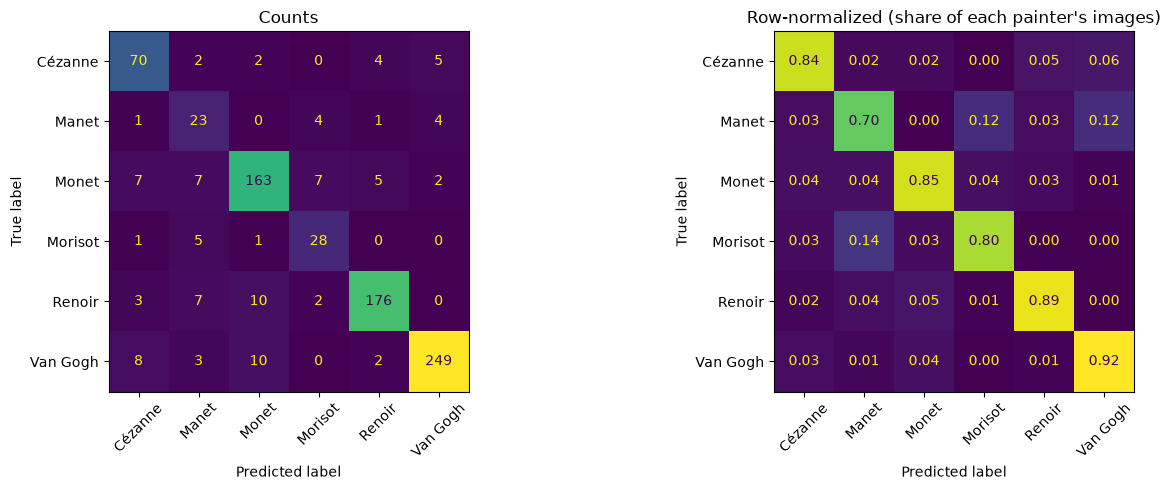

artist    pred_artist
Van Gogh  Monet          10
Renoir    Monet          10
Van Gogh  Cézanne        8
Monet     Cézanne        7
Renoir    Manet           7
Monet     Manet           7
          Morisot         7
Morisot   Manet           5
dtype: int64

In [23]:
# Confusion matrix

cm = confusion_matrix(res["y_true"], res["y_pred"])
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ConfusionMatrixDisplay(cm, display_labels=classes).plot(ax=axes[0], cmap="viridis", colorbar=False, xticks_rotation=45)
axes[0].set_title("Counts")
ConfusionMatrixDisplay(confusion_matrix(res["y_true"], res["y_pred"], normalize="true"),
                       display_labels=classes).plot(ax=axes[1], cmap="viridis", colorbar=False,
                                                    xticks_rotation=45, values_format=".2f")
axes[1].set_title("Row-normalized (share of each painter's images)")
plt.tight_layout(); plt.show()

# most frequent confusions, as a table
errors = res[~res["correct"]]
display(pd.crosstab(errors["artist"], errors["pred_artist"]).stack()
        .loc[lambda s: s > 0].sort_values(ascending=False).head(8))

### A few examples of wrong predictions

**One observation from the per-class evaluation of the test set and the model's confidence**: 

**The model is confident even when it is wrong.** The mean confidence of the wrong predictions is 0.67 to 0.72 in every class. The model is overconfident, probably as a consequence of fine-tuning with a low training loss (the training F1 reached about 0.94) and of the class-weighted loss.

In [34]:
print(classification_report(res["y_true"], res["y_pred"], target_names=classes, zero_division=0))

rows = []
for i, c in enumerate(classes):
    cls = res[res["y_true"] == i]
    rows.append({
        "artist": c,
        "n test": len(cls),
        "recall (all)": cls["correct"].mean(),
        "mean conf, correct": cls.loc[cls["correct"], "conf"].mean(),
        "mean conf, wrong": cls.loc[~cls["correct"], "conf"].mean(),
    })
print(pd.DataFrame(rows).round(2))

              precision    recall  f1-score   support

    Cézanne       0.78      0.84      0.81        83
       Manet       0.49      0.70      0.57        33
       Monet       0.88      0.85      0.86       191
     Morisot       0.68      0.80      0.74        35
      Renoir       0.94      0.89      0.91       198
    Van Gogh       0.96      0.92      0.94       272

    accuracy                           0.87       812
   macro avg       0.79      0.83      0.81       812
weighted avg       0.88      0.87      0.88       812

     artist  n test  recall (all)  mean conf, correct  mean conf, wrong
0  Cézanne      83          0.84                0.94              0.69
1     Manet      33          0.70                0.86              0.72
2     Monet     191          0.85                0.89              0.68
3   Morisot      35          0.80                0.86              0.70
4    Renoir     198          0.89                0.97              0.67
5  Van Gogh     272      

The wrong predictions of the fine-tuned model have one thing in common: they overwhelmingly occur between painters whose styles genuinely overlap, not between painters who look unlike each other. The test confusion matrix shows the largest error groups between Renoir and Monet, who share light and loose brushwork and worked side by side, between Manet and Morisot, who both paint figures with loose, sketch-like handling, and between Van Gogh and Cézanne, two Post-Impressionists with strong color and visible strokes. Monet's errors are scattered across all the other painters, which fits his role as the reference point of the style, since his paintings share traits with each of them.

Manet and Morisot are the weakest classes, and the reason is partly statistical: with only about 33 and 35 test images, each misclassified painting moves their recall by about 3 points, so their scores and the specific confusions between them rest on a handful of paintings and are uncertain. The training set is also small for them (about 235 and 242 images in total), which gives the model less material to learn from. Manet's style additionally ranges from flat, dark early work to loose outdoor scenes close to Impressionism, so his label becomes a catch-all for ambiguous paintings, with a precision of only about 0.49.

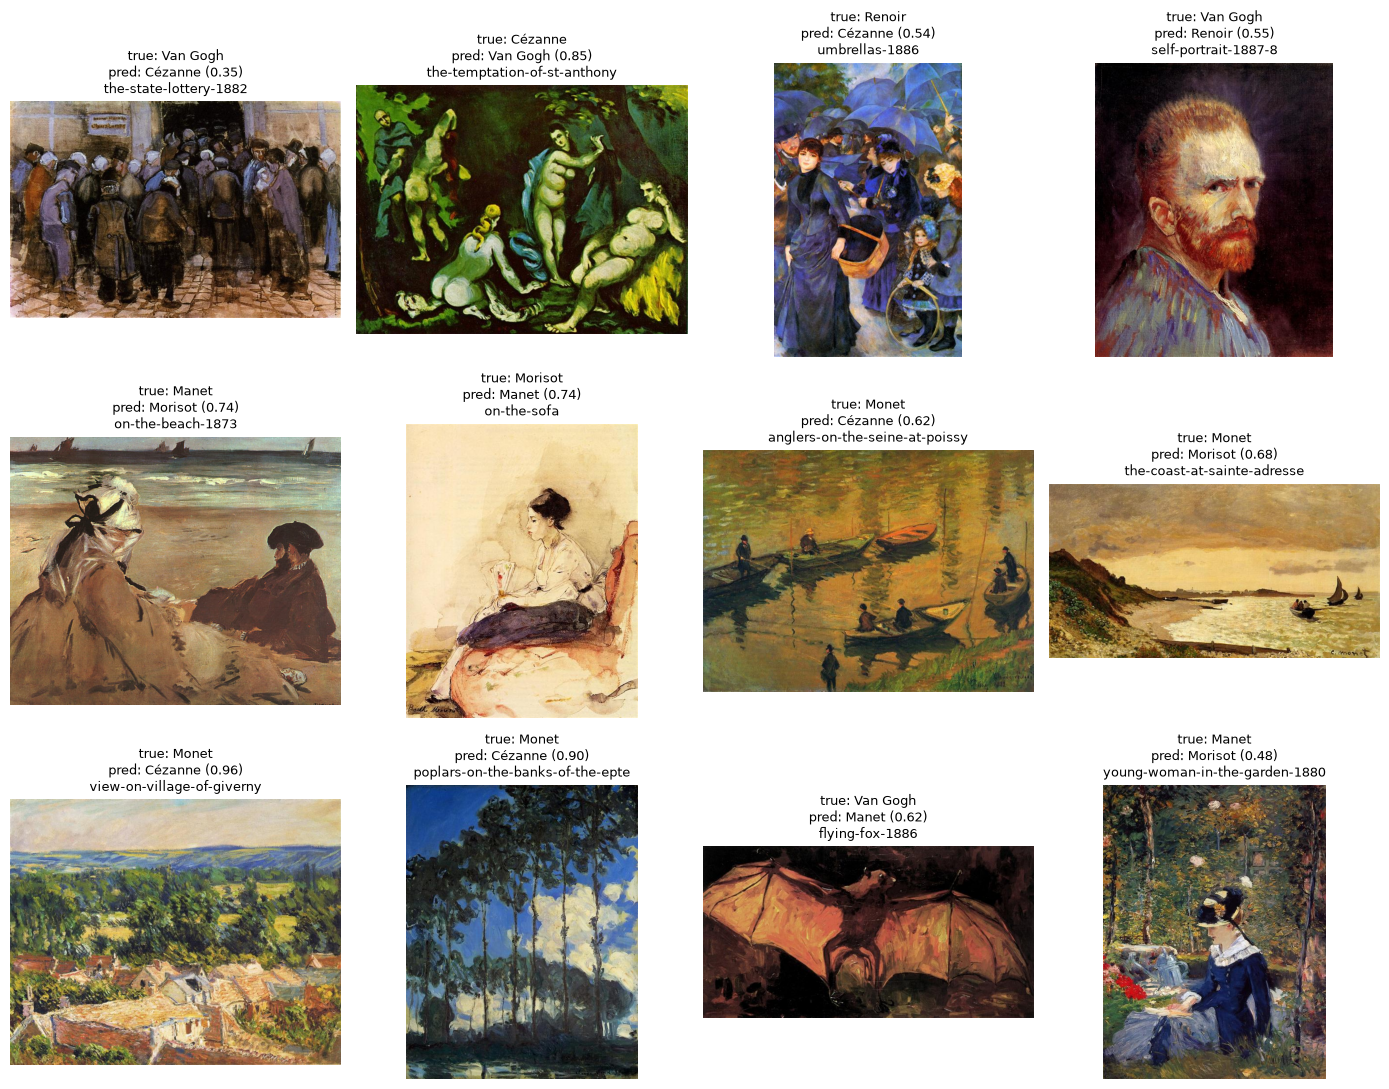

In [64]:
worst = res[~res["correct"]].sort_values("conf", ascending=False).sample(12)

fig, axes = plt.subplots(3, 4, figsize=(14, 11))
for ax, (_, r) in zip(axes.ravel(), worst.iterrows()):
    ax.imshow(Image.open(r["path"]).convert("RGB"))
    ax.set_title(f"true: {r['artist']}\npred: {r['pred_artist']} ({r['conf']:.2f})\n"
                 + textwrap.shorten(str(r["title"]), 38), fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

---
## 4. Save, reload, predict

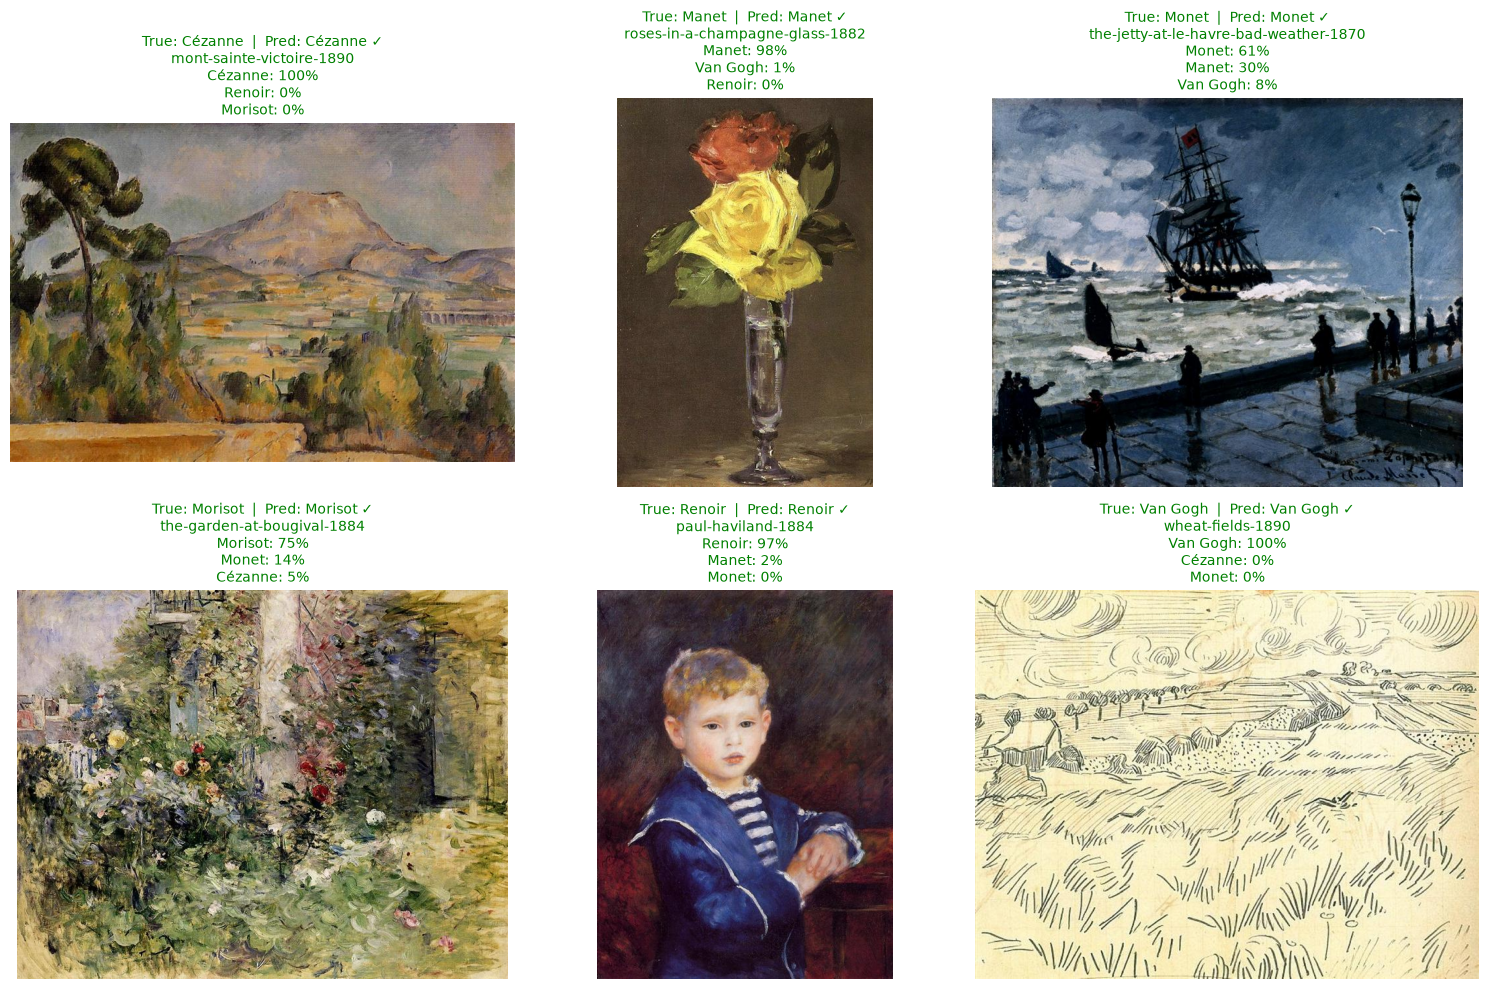

,artist,predicted,confidence,correct
title,,,,
mont-sainte-victoire-1890,Cézanne,Cézanne,1.00,True
roses-in-a-champagne-glass-1882,Manet,Manet,0.98,True
the-jetty-at-le-havre-bad-weather-1870,Monet,Monet,0.61,True
the-garden-at-bougival-1884,Morisot,Morisot,0.75,True
paul-haviland-1884,Renoir,Renoir,0.97,True
wheat-fields-1890,Van Gogh,Van Gogh,1.00,True


In [31]:
# one random painting per painter from the test set
sample = pd.concat(
    [g.sample(1, random_state=RANDOM_STATE+2) for _, g in test.groupby("artist")]
).reset_index(drop=True)

# predict (no shuffling, so rows stay aligned)
ft_loaded.eval()
dl = DataLoader(PaintingDataset(sample, class_to_idx), batch_size=len(sample))
with torch.no_grad():
    x, _ = next(iter(dl))
    probs = ft_loaded.predict_proba(x.to(device)).cpu().numpy()

# plot
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, (_, row), p in zip(axes.ravel(), sample.iterrows(), probs):
    top = np.argsort(p)[::-1][:3]
    pred = classes[top[0]]
    ok = pred == row["artist"]
    ax.imshow(Image.open(row["path"]).convert("RGB"))
    ax.axis("off")
    ax.set_title(
        f"True: {row['artist']}  |  Pred: {pred} {'✓' if ok else '✗'}\n"
        + textwrap.shorten(str(row["title"]), 45) + "\n"
        + "\n".join(f"{classes[i]}: {p[i]:.0%}" for i in top),
        fontsize=10, color="green" if ok else "red",
    )
plt.tight_layout()
plt.show()

# summary table
summary = sample[["artist", "title"]].copy()
summary["predicted"] = [classes[p.argmax()] for p in probs]
summary["confidence"] = [round(float(p.max()), 2) for p in probs]
summary["correct"] = summary["artist"] == summary["predicted"]
display(summary.set_index('title'))

---
## 5. Conclusions and limitations

Overall, this model can be used as an assistive tool, not as an authority. The fine-tuned MobileNetV2 reached a test accuracy of 0.873 and a macro-F1 of 0.806 (95% CI 0.766 to 0.840). The majority-class baseline scored 0.335 and 0.084, and the scratch CNN scored a validation macro-F1 of about 0.51. The validation and test scores agree closely, so the estimate appears honest. The model learned stylistic signal and not just the class distribution.

The use case it fits is a **first-pass suggestion** for students, museum visitors, or cataloguers: propose the likely painter of an unlabeled image, or flag a catalog entry whose label disagrees with a confident prediction, so that an expert can review it. In this setting, a wrong suggestion is corrected by review and does little harm. The model is also suitable for educational demos, such as showing the top-2 predictions with probabilities and explaining which stylistic features the painters share and predictions for Van Gogh, Renoir, and Monet (F1 of about 0.86 to 0.94) are reliable enough to use with light review.

**Where it should not be trusted**

- **Manet.** His F1 is the lowest (about 0.58). The model predicts him far more often than he occurs, so about half of the “Manet” labels are wrong. His style ranges from flat, dark early work to loose outdoor scenes, and the model tends to use his label for ambiguous Impressionist paintings. A Manet prediction should always be treated as a candidate for expert review. Morisot is milder but similar (precision about 0.68).
- **Any painter outside the six.** The model is a closed-set classifier and must choose one of six labels, so a painting by Degas, Pissarro, or Sisley will be attributed confidently to someone in the set, most likely a stylistic neighbor.
- **Authentication, provenance, or valuation.** An accuracy of 87% on in-distribution images cannot support decisions where a wrong attribution has legal or financial consequences, and the model captures broad style, not the evidence an expert uses.
- **Images unlike the training data.** The model was trained and tested on WikiArt reproductions. Photographs taken at angles, in poor light, or of framed paintings, sketches, drawings, prints, and heavy crops are outside that distribution, and performance there is unknown.
- **Its own confidence.** The model is overconfident: even its wrong predictions carry a mean confidence of about 0.7, so most errors still pass the filter. A high probability is not a guarantee, and the confidence is least informative for Manet and Morisot.
- **Fine distinctions between neighbors.** The remaining errors concentrate between stylistic neighbors (Renoir and Monet, Manet and Morisot, Van Gogh and Cézanne), where the model should not be treated as more reliable than a trained eye.
  
**Limitations of the evaluation**

- Manet and Morisot have only about 33 and 35 test images, so their per-class scores could shift by several points on a different sample. This is also why the macro-F1 interval is about ±0.04 wide.
- The validation set was used for early stopping, model comparison, so the validation scores are slightly optimistic. The test set was evaluated once.
- The 224×224 input compresses fine brushwork, and WikiArt labels and metadata may contain errors or near-duplicates that the deduplication did not catch.

**What I would do with another week**

1. **Make the output more precise**: choose a threshold on validation data, and show the top-2 predictions with a reliability diagram.
2. **Improve Manet and Morisot**: tune class or probability weights on out-of-fold predictions, add stronger augmentation for these classes, and inspect the most confident errors visually for sketches, duplicates, or label noise.
3. **Preserve brushwork**: test higher-resolution inputs.
4. **Compare other backbones**: for example EfficientNet, or CLIP embeddings with a logistic regression.
5. **Stress-test generalization**: evaluate on paintings from museum open-access collections outside WikiArt and on photographs of paintings.
6. **Tune the fine-tuning**: try unfreezing two blocks instead of four, and more regularization, since the training macro-F1 (about 0.94) was far above the validation score.